In [ ]:
import torch
import os
from pathlib import Path
 
# Check if GPU is available 
DEVICE = 'cuda' if torch.cuda.is_available() else "cpu"
 
# current directory
HOME = os.getcwd()
EXPERIMENT_NAME="building_defect_yolo_nas_m"
# models/ is the shared top-level directory (../models from this project),
# also read by batch_inference. SuperGradients writes checkpoints to
# {CHECKPOINT_DIR}/{EXPERIMENT_NAME}/RUN_*/...
CHECKPOINT_DIR = str(Path(HOME).parent / "models")

In [ ]:
from super_gradients.training import Trainer
 
""" 
Trainer --> Initialize the Trainer for the YOLO-NAS model
Trainer is responsible for managing the training process, including data loading, model training, and evaluation.
trainer is an instance of the Trainer class from the super_gradients.training module.
"""
trainer = Trainer(experiment_name=EXPERIMENT_NAME, ckpt_root_dir=CHECKPOINT_DIR)
  
IMG_SIZE = [640, 640]  # Input image size for the model

# Dataset , Label information
dataset_params = {
    'data_dir': f"{HOME}/training-data",
    'train_images_dir':'train/images',
    'train_labels_dir':'train/labels',
    'val_images_dir':'val/images',
    'val_labels_dir':'val/labels',
    'classes': [line.strip() for line in open(f"{HOME}/training-data/classes.txt") if line.strip()], # labels here
    'input_dim': IMG_SIZE
}

In [4]:
from super_gradients.training.dataloaders.dataloaders import (
    coco_detection_yolo_format_train, coco_detection_yolo_format_val)
 
# you can increase this number depending on your GPU, more batch size means faster training
BATCH_SIZE = 8
NUM_WORKERS = min(8, max(2, os.cpu_count() or 2))

train_transforms = [
    {
        "DetectionMosaic": {
            "input_dim": IMG_SIZE,
            "prob": 0.7
        }
    },
    {
        "DetectionRandomAffine": {
            "degrees": 10.0,
            "translate": 0.1,
            "scales": [0.5, 1.5],
            "shear": 2.0,
            "target_size": IMG_SIZE,
            "filter_box_candidates": True,
            "wh_thr": 2,
            "area_thr": 0.1,
            "ar_thr": 20
        }
    },
    {
        "DetectionMixup": {
            "input_dim": IMG_SIZE,
            "mixup_scale": [0.5, 1.5],
            "prob": 0.2,
            "flip_prob": 0.5
        }
    },
    {
        "DetectionHSV": {
            "prob": 0.5,
            "hgain": 5,
            "sgain": 30,
            "vgain": 30
        }
    },
    {
        "DetectionHorizontalFlip": {
            "prob": 0.5
        }
    },
    {
        "DetectionPaddedRescale": {
            "input_dim": IMG_SIZE
        }
    },
    {
        "DetectionTargetsFormatTransform": {
            "input_dim": IMG_SIZE,
            "output_format": "LABEL_CXCYWH"
        }
    }
]

val_transforms = [
    {
        "DetectionPaddedRescale": {
            "input_dim": IMG_SIZE
        }
    },
    {
        "DetectionTargetsFormatTransform": {
            "input_dim": IMG_SIZE,
            "output_format": "LABEL_CXCYWH"
        }
    }
]
 
train_data = coco_detection_yolo_format_train(
    dataset_params={
        'data_dir': dataset_params['data_dir'],
        'images_dir': dataset_params['train_images_dir'],
        'labels_dir': dataset_params['train_labels_dir'],
        'classes': dataset_params['classes'],
        'transforms': train_transforms
    },
    dataloader_params={
        'batch_size': BATCH_SIZE,
        'num_workers': NUM_WORKERS
    }
)
 
val_data = coco_detection_yolo_format_val(
    dataset_params={
        'data_dir': dataset_params['data_dir'],
        'images_dir': dataset_params['val_images_dir'],
        'labels_dir': dataset_params['val_labels_dir'],
        'classes': dataset_params['classes'],
        'transforms': val_transforms
    },
    dataloader_params={
        'batch_size': BATCH_SIZE,
        'num_workers': NUM_WORKERS
    }
)


[2026-05-08 18:00:53] INFO - detection_dataset.py - Dataset Initialization in progress. `cache_annotations=True` causes the process to take longer due to full dataset indexing.
Indexing dataset annotations: 100%|██████████| 19198/19198 [00:18<00:00, 1045.54it/s]
[2026-05-08 18:01:11] INFO - detection_dataset.py - Dataset Initialization in progress. `cache_annotations=True` causes the process to take longer due to full dataset indexing.
Indexing dataset annotations:  94%|█████████▍| 2005/2133 [00:02<00:00, 1012.93it/s]

Indexing dataset annotations: 100%|██████████| 2133/2133 [00:02<00:00, 941.70it/s] 


[2026-05-08 18:01:14] INFO - detection_dataset.py - Dataset Initialization in progress. `cache_annotations=True` causes the process to take longer due to full dataset indexing.


[CopyPaste] class 0: 6899 crops in pool
[CopyPaste] class 2: 3638 crops in pool
[CopyPaste] class 3: 1252 crops in pool


Indexing dataset annotations: 100%|██████████| 19198/19198 [00:00<00:00, 20652.08it/s]


Copy-paste augmentation enabled.


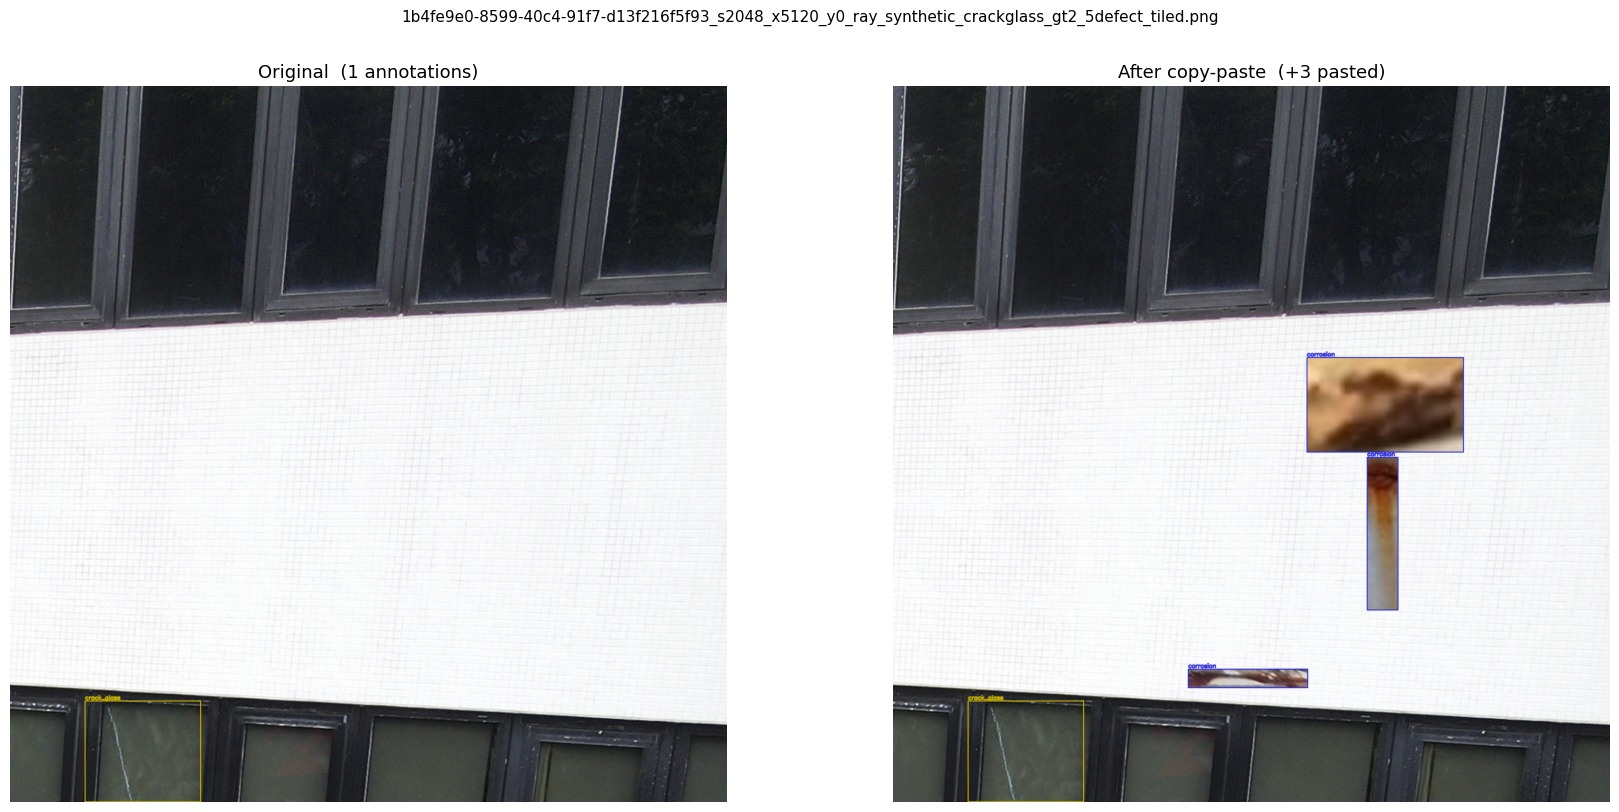

In [5]:
from copy_paste_aug import ClassAwareCopyPaste

USE_COPY_PASTE = False  # disabled by default; set True to enable ClassAwareCopyPaste (see copy_paste_aug.py)

if USE_COPY_PASTE:
    _copy_paste = ClassAwareCopyPaste(
        images_dir=f"{dataset_params['data_dir']}/{dataset_params['train_images_dir']}",
        labels_dir=f"{dataset_params['data_dir']}/{dataset_params['train_labels_dir']}",
        rare_classes=[0, 2, 3],  # corrosion, spall, plant_growth
        paste_prob=0.5,
        max_paste=3,
        scale_range=(0.05, 0.25),
        max_overlap=0.1,
    )
    train_data = coco_detection_yolo_format_train(
        dataset_params={
            'data_dir': dataset_params['data_dir'],
            'images_dir': dataset_params['train_images_dir'],
            'labels_dir': dataset_params['train_labels_dir'],
            'classes': dataset_params['classes'],
            'transforms': [_copy_paste] + train_transforms
        },
        dataloader_params={
            'batch_size': BATCH_SIZE,
            'num_workers': NUM_WORKERS,
        }
    )
    print("Copy-paste augmentation enabled.")

    # --- Preview ---
    import cv2
    import numpy as np
    import matplotlib.pyplot as plt
    import random
    from pathlib import Path
    from super_gradients.training.samples import DetectionSample

    _img_dir = Path(f"{dataset_params['data_dir']}/{dataset_params['train_images_dir']}")
    _lbl_dir = Path(f"{dataset_params['data_dir']}/{dataset_params['train_labels_dir']}")
    _class_names = dataset_params['classes']
    _colors = [(220, 50, 50), (50, 200, 50), (50, 50, 220), (200, 180, 0), (0, 180, 200)]

    _img_files = [p for p in _img_dir.iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}]
    _img_path = random.choice(_img_files)
    _lbl_path = _lbl_dir / (_img_path.stem + ".txt")

    _img = cv2.imread(str(_img_path))
    _H, _W = _img.shape[:2]

    _bboxes, _labels = [], []
    if _lbl_path.exists():
        for _line in _lbl_path.read_text().strip().splitlines():
            if not _line.strip():
                continue
            _p = _line.split()
            _cls = int(_p[0])
            _cx, _cy, _w, _h = float(_p[1]), float(_p[2]), float(_p[3]), float(_p[4])
            _bboxes.append([(_cx - _w/2)*_W, (_cy - _h/2)*_H, (_cx + _w/2)*_W, (_cy + _h/2)*_H])
            _labels.append(_cls)

    _orig_sample = DetectionSample(
        image=_img,
        bboxes_xyxy=np.array(_bboxes, dtype=np.float32).reshape(-1, 4) if _bboxes else np.zeros((0, 4), dtype=np.float32),
        labels=np.array(_labels, dtype=np.int32),
    )

    # Retry until at least one instance is pasted (paste_prob may not fire every call)
    _aug_sample = _orig_sample
    for _ in range(20):
        _aug_sample = _copy_paste.apply_to_sample(_orig_sample)
        if len(_aug_sample.labels) > len(_orig_sample.labels):
            break

    def _draw_boxes(img, bboxes, labels, class_names, colors):
        out = img.copy()
        for bbox, label in zip(bboxes, labels):
            x1, y1, x2, y2 = map(int, bbox)
            color = colors[label % len(colors)]
            cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)
            cv2.putText(out, class_names[label], (x1, max(12, y1 - 4)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2, cv2.LINE_AA)
        return out

    _vis_orig = _draw_boxes(_img, _orig_sample.bboxes_xyxy, _orig_sample.labels, _class_names, _colors)
    _vis_aug  = _draw_boxes(_aug_sample.image, _aug_sample.bboxes_xyxy, _aug_sample.labels, _class_names, _colors)

    _n_pasted = len(_aug_sample.labels) - len(_orig_sample.labels)
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    axes[0].imshow(cv2.cvtColor(_vis_orig, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Original  ({len(_orig_sample.labels)} annotations)", fontsize=13)
    axes[0].axis('off')
    axes[1].imshow(cv2.cvtColor(_vis_aug, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f"After copy-paste  (+{_n_pasted} pasted)", fontsize=13)
    axes[1].axis('off')
    plt.suptitle(_img_path.name, fontsize=11, y=1.01)
    plt.tight_layout()
    plt.show()

else:
    print("Copy-paste augmentation disabled.")

In [6]:
import torch
from torch.utils.data import DataLoader, WeightedRandomSampler
from tqdm.auto import tqdm

USE_WEIGHTED_SAMPLING = False

if USE_WEIGHTED_SAMPLING:
    dataset = train_data.dataset
    num_classes = len(dataset_params["classes"])

    def extract_labels(sample):
        # common shapes in SG detection datasets
        if isinstance(sample, (tuple, list)) and len(sample) >= 2:
            target = sample[1]
        elif isinstance(sample, dict):
            target = sample.get("targets") or sample.get("target") or sample.get("labels")
        else:
            target = sample

        # target can be Nx5 (class, cx, cy, w, h) or dict with "labels"
        if isinstance(target, dict) and "labels" in target:
            labels = target["labels"]
        else:
            labels = target[:, 0] if hasattr(target, "shape") and target.ndim == 2 else target

        if hasattr(labels, "detach"):
            labels = labels.detach().cpu()
        return torch.as_tensor(labels, dtype=torch.long)

    print("Counting class occurrences per box...")
    class_counts = torch.zeros(num_classes)
    for i in tqdm(range(len(dataset)), desc="Scan dataset (class counts)"):
        labels = extract_labels(dataset[i])
        if labels.numel() > 0:
            class_counts.scatter_add_(0, labels, torch.ones_like(labels, dtype=class_counts.dtype))

    print("Class counts:", class_counts.tolist())

    print("Computing inverse-frequency class weights...")
    class_weights = class_counts.sum() / torch.clamp(class_counts, min=1)
    print("Class weights:", class_weights.tolist())

    print("Assigning per-image sampling weights...")
    sample_weights = []
    for i in tqdm(range(len(dataset)), desc="Compute sample weights"):
        labels = extract_labels(dataset[i])
        w = 0.0 if labels.numel() == 0 else class_weights[labels].max().item()
        sample_weights.append(w)

    sample_weights = torch.tensor(sample_weights, dtype=torch.float)
    print("Sample weights summary:",
          f"min={sample_weights.min().item():.4f},",
          f"max={sample_weights.max().item():.4f},",
          f"mean={sample_weights.mean().item():.4f}")

    print("Building WeightedRandomSampler...")
    sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

    print("Rebuilding train DataLoader with sampler...")
    train_data = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        sampler=sampler,
        num_workers=NUM_WORKERS,
        collate_fn=train_data.collate_fn,
        pin_memory=True,
    )

    print("Weighted sampling enabled.")
else:
    dataset = train_data.dataset
    train_data = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        collate_fn=train_data.collate_fn,
        pin_memory=True,
    )
    print("Weighted sampling disabled — using default DataLoader.")


/home/uavc/.pyenv/versions/yolonas-training/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Weighted sampling disabled — using default DataLoader.


In [ ]:
from super_gradients.training import models

MODEL_ARCH = "yolo_nas_m"

# Choose initialization: "coco" for COCO pretrained or "checkpoint" to fine-tune from a checkpoint
INIT_SOURCE = "coco"  # "coco" or "checkpoint"
CHECKPOINT_PATH = "../models/building_defect_yolo_nas_m/RUN_20260124_162702_537141/ckpt_best.pth"  # set to a .pth path when INIT_SOURCE="checkpoint"

if INIT_SOURCE == "coco":
    model = models.get(
        MODEL_ARCH,
        num_classes=len(dataset_params['classes']),
        pretrained_weights="coco"
    )
elif INIT_SOURCE == "checkpoint":
    if not CHECKPOINT_PATH:
        raise ValueError("CHECKPOINT_PATH must be set when INIT_SOURCE='checkpoint'")
    model = models.get(
        MODEL_ARCH,
        num_classes=len(dataset_params['classes']),
        checkpoint_path=CHECKPOINT_PATH
    )
else:
    raise ValueError(f"Unknown INIT_SOURCE: {INIT_SOURCE}")


In [ ]:
from super_gradients.training.losses import PPYoloELoss
from super_gradients.training.metrics import DetectionMetrics_050
from super_gradients.training.models.detection_models.pp_yolo_e import PPYoloEPostPredictionCallback
 
# Epoch Number
MAX_EPOCHS = 100

# Resume training from a checkpoint (set to ckpt_latest.pth)
RESUME_PATH = "../models/building_defect_yolo_nas_m/RUN_20260325_104150_384988/ckpt_latest.pth"
RESUME_TRAINING = False  # Set to True to resume training from the checkpoint
 
train_params = {
    'silent_mode': False,
    "average_best_models":True,
    "warmup_mode": "linear_epoch_step",
    "warmup_initial_lr": 1e-6,
    "lr_warmup_epochs": 3,
    "initial_lr": 5e-4,
    "lr_mode": "cosine",
    "cosine_final_lr_ratio": 0.1,
    "batch_accumulate": 4,
 
    "optimizer": "AdamW",
    "optimizer_params": {"weight_decay": 0.0001},
    "zero_weight_decay_on_bias_and_bn": True,
    "ema": True,
    "ema_params": {"decay": 0.9999, "decay_type": "threshold"},
    "max_epochs": MAX_EPOCHS,
    "resume": RESUME_TRAINING,
    "resume_path": RESUME_PATH if RESUME_TRAINING else None,
    "resume_strict_load": False,
    "mixed_precision":  True , # TRUE BY DEFAULT , depending to GPU setting this to True might cause nan value problem in metrics
    "loss": PPYoloELoss(
        use_static_assigner=False,
        num_classes=len(dataset_params['classes']),
        reg_max=16
    ),
    "valid_metrics_list": [
        DetectionMetrics_050(
            score_thres=0.1,
            top_k_predictions=300,
            num_cls=len(dataset_params['classes']),
            normalize_targets=True,
            post_prediction_callback=PPYoloEPostPredictionCallback(
                score_threshold=0.01,
                nms_top_k=1000,
                max_predictions=300,
                nms_threshold=0.5
            )
        )
    ],
    "metric_to_watch": 'mAP@0.50'
}


In [9]:
from super_gradients.training.utils.callbacks import Callback

class NotebookMetricsRecorder(Callback):
    def __init__(self):
        self.epoch_history = []

    @staticmethod
    def _to_float(value):
        if hasattr(value, "item"):
            value = value.item()
        return float(value)

    def _get_epoch_entry(self, epoch):
        for entry in self.epoch_history:
            if entry["epoch"] == epoch:
                return entry
        new_entry = {"epoch": epoch}
        self.epoch_history.append(new_entry)
        return new_entry

    def on_train_loader_end(self, context):
        if not context.metrics_dict:
            return
        epoch_entry = self._get_epoch_entry(context.epoch)
        for name, value in context.metrics_dict.items():
            epoch_entry[f"Train/{name}"] = self._to_float(value)

    def on_validation_loader_end(self, context):
        if not context.metrics_dict:
            return
        epoch_entry = self._get_epoch_entry(context.epoch)
        for name, value in context.metrics_dict.items():
            epoch_entry[f"Valid/{name}"] = self._to_float(value)

metrics_recorder = NotebookMetricsRecorder()
train_params.setdefault("phase_callbacks", []).append(metrics_recorder)


In [10]:
trainer.train(
    model=model,
    training_params=train_params,
    train_loader=train_data,
    valid_loader=val_data
)

[2026-05-08 18:01:17] WARNING - sg_trainer.py - Train dataset size % batch_size != 0 and drop_last=False, this might result in smaller last batch.
[2026-05-08 18:01:20] INFO - sg_trainer.py - Starting a new run with `run_id=RUN_20260508_180120_151273`
[2026-05-08 18:01:20] INFO - sg_trainer.py - Checkpoints directory: /home/uavc/projects/yolonas-training/checkpoints/building_defect_yolo_nas_m/RUN_20260508_180120_151273
[2026-05-08 18:01:20] INFO - sg_trainer.py - Using EMA with params {'decay': 0.9999, 'decay_type': 'threshold'}
/home/uavc/.pyenv/versions/yolonas-training/lib/python3.10/site-packages/super_gradients/common/registry/registry.py:72: DeprecationWarning: Object name `linear_epoch_step` is now deprecated. Please replace it with `LinearEpochLRWarmup`.
  warnings.warn(f"Object name `{name}` is now deprecated. Please replace it with `{deprecated_names[name]}`.", DeprecationWarning)
/home/uavc/.pyenv/versions/yolonas-training/lib/python3.10/site-packages/super_gradients/trainin

The console stream is now moved to /home/uavc/projects/yolonas-training/checkpoints/building_defect_yolo_nas_m/RUN_20260508_180120_151273/console_May08_18_01_20.txt


/home/uavc/.pyenv/versions/yolonas-training/lib/python3.10/site-packages/torch/utils/data/_utils/pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at /pytorch/aten/src/ATen/native/Memory.cpp:46.)
  return data.pin_memory(device)
/home/uavc/.pyenv/versions/yolonas-training/lib/python3.10/site-packages/torch/utils/data/_utils/pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at /pytorch/aten/src/ATen/native/Memory.cpp:31.)
  return data.pin_memory(device)
[2026-05-08 18:01:24] INFO - sg_trainer_utils.py - TRAINING PARAMETERS:
    - Mode:                         Single GPU
    - Number of GPUs:               1          (1 available on the machine)
    - Full dataset size:            19198      (len(train_set))
    - Batch size per GPU:           8          (batch_size)
    - Batch Accu

SUMMARY OF EPOCH 0
├── Train
│   ├── Ppyoloeloss/loss_cls = 1.9399
│   ├── Ppyoloeloss/loss_iou = 0.718
│   ├── Ppyoloeloss/loss_dfl = 0.674
│   └── Ppyoloeloss/loss = 3.3319
└── Validation
    ├── Ppyoloeloss/loss_cls = 1.8164
    ├── Ppyoloeloss/loss_iou = 0.9775
    ├── Ppyoloeloss/loss_dfl = 0.8201
    ├── Ppyoloeloss/loss = 3.614
    ├── Precision@0.50 = 0.0138
    ├── Recall@0.50 = 0.0172
    ├── Map@0.50 = 0.0024
    ├── F1@0.50 = 0.0093
    └── Best_score_threshold = 0.11



Validating epoch 1: 100%|██████████| 267/267 [00:46<00:00,  5.70it/s]
[2026-05-08 18:23:56] INFO - base_sg_logger.py - Checkpoint saved in /home/uavc/projects/yolonas-training/checkpoints/building_defect_yolo_nas_m/RUN_20260508_180120_151273/ckpt_best.pth
[2026-05-08 18:23:56] INFO - sg_trainer.py - Best checkpoint overriden: validation mAP@0.50: 0.1730256974697113


...

Validating epoch 98: 100%|██████████| 267/267 [00:44<00:00,  5.98it/s]
[2026-05-09 12:12:57] INFO - base_sg_logger.py - Checkpoint saved in /home/uavc/projects/yolonas-training/checkpoints/building_defect_yolo_nas_m/RUN_20260508_180120_151273/ckpt_best.pth
[2026-05-09 12:12:57] INFO - sg_trainer.py - Best checkpoint overriden: validation mAP@0.50: 0.7239886522293091


SUMMARY OF EPOCH 98
├── Train
│   ├── Ppyoloeloss/loss_cls = 0.7825
│   │   ├── Epoch N-1      = 0.7861 (↘ -0.0036)
│   │   └── Best until now = 0.7861 (↘ -0.0036)
│   ├── Ppyoloeloss/loss_iou = 0.3915
│   │   ├── Epoch N-1      = 0.393  (↘ -0.0015)
│   │   └── Best until now = 0.393  (↘ -0.0015)
│   ├── Ppyoloeloss/loss_dfl = 0.4061
│   │   ├── Epoch N-1      = 0.4075 (↘ -0.0014)
│   │   └── Best until now = 0.4071 (↘ -0.001)
│   └── Ppyoloeloss/loss = 1.5802
│       ├── Epoch N-1      = 1.5866 (↘ -0.0065)
│       └── Best until now = 1.5866 (↘ -0.0065)
└── Validation
    ├── Ppyoloeloss/loss_cls = 0.8665
    │   ├── Epoch N-1      = 0.8689 (↘ -0.0023)
    │   └── Best until now = 0.8689 (↘ -0.0023)
    ├── Ppyoloeloss/loss_iou = 0.5137
    │   ├── Epoch N-1      = 0.5139 (↘ -0.0002)
    │   └── Best until now = 0.5139 (↘ -0.0002)
    ├── Ppyoloeloss/loss_dfl = 0.4555
    │   ├── Epoch N-1      = 0.456  (↘ -0.0004)
    │   └── Best until now = 0.456  (↘ -0.0004)
    ├── Ppyoloeloss/lo

Validating epoch 99: 100%|██████████| 267/267 [00:44<00:00,  5.95it/s]
[2026-05-09 12:24:14] INFO - base_sg_logger.py - Checkpoint saved in /home/uavc/projects/yolonas-training/checkpoints/building_defect_yolo_nas_m/RUN_20260508_180120_151273/ckpt_best.pth
[2026-05-09 12:24:14] INFO - sg_trainer.py - Best checkpoint overriden: validation mAP@0.50: 0.7247893214225769


SUMMARY OF EPOCH 99
├── Train
│   ├── Ppyoloeloss/loss_cls = 0.7824
│   │   ├── Epoch N-1      = 0.7825 (↘ -1e-04)
│   │   └── Best until now = 0.7825 (↘ -1e-04)
│   ├── Ppyoloeloss/loss_iou = 0.391
│   │   ├── Epoch N-1      = 0.3915 (↘ -0.0005)
│   │   └── Best until now = 0.3915 (↘ -0.0005)
│   ├── Ppyoloeloss/loss_dfl = 0.4043
│   │   ├── Epoch N-1      = 0.4061 (↘ -0.0019)
│   │   └── Best until now = 0.4061 (↘ -0.0019)
│   └── Ppyoloeloss/loss = 1.5777
│       ├── Epoch N-1      = 1.5802 (↘ -0.0024)
│       └── Best until now = 1.5802 (↘ -0.0024)
└── Validation
    ├── Ppyoloeloss/loss_cls = 0.8646
    │   ├── Epoch N-1      = 0.8665 (↘ -0.0019)
    │   └── Best until now = 0.8665 (↘ -0.0019)
    ├── Ppyoloeloss/loss_iou = 0.5131
    │   ├── Epoch N-1      = 0.5137 (↘ -0.0006)
    │   └── Best until now = 0.5137 (↘ -0.0006)
    ├── Ppyoloeloss/loss_dfl = 0.4548
    │   ├── Epoch N-1      = 0.4555 (↘ -0.0008)
    │   └── Best until now = 0.4555 (↘ -0.0008)
    ├── Ppyoloeloss/loss

[2026-05-09 12:24:30] INFO - sg_trainer.py - RUNNING ADDITIONAL TEST ON THE AVERAGED MODEL...
Validating epoch 100: 100%|██████████| 267/267 [00:44<00:00,  5.93it/s]
[2026-05-09 12:25:15] INFO - base_sg_logger.py - [CLEANUP] - Successfully stopped system monitoring process


,epoch,Valid/Recall@0.50,Valid/Precision@0.50,Valid/mAP@0.50,Valid/F1@0.50,Valid/PPYoloELoss/loss
0,0,0.017218,0.013822,0.002434,0.009261,3.613998
1,1,0.381285,0.103362,0.173026,0.161748,2.647668
2,2,0.484911,0.102429,0.239734,0.168493,2.532473
3,3,0.483952,0.126379,0.243196,0.199107,2.555899
4,4,0.472717,0.140526,0.257153,0.215325,2.565253
...,...,...,...,...,...,...
95,95,0.832795,0.175878,0.720055,0.284884,1.845216
96,96,0.831861,0.176320,0.720668,0.285392,1.841865
97,97,0.836561,0.178500,0.723688,0.288467,1.838718
98,98,0.836927,0.179643,0.723989,0.290041,1.835816


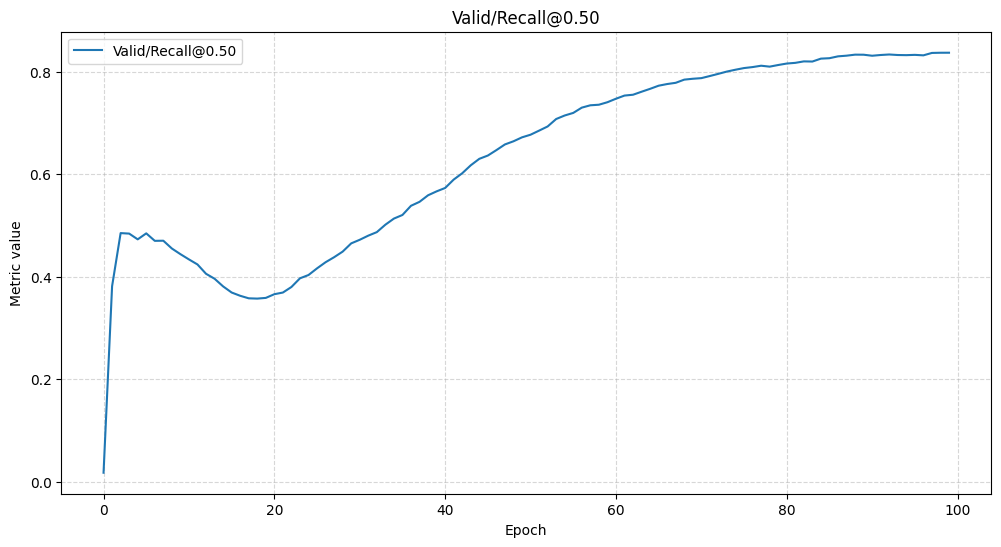

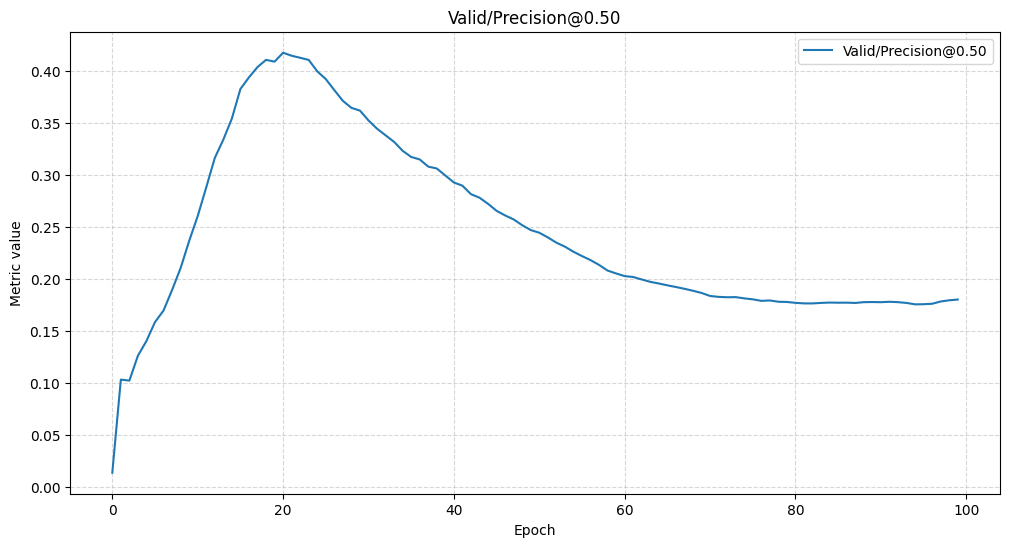

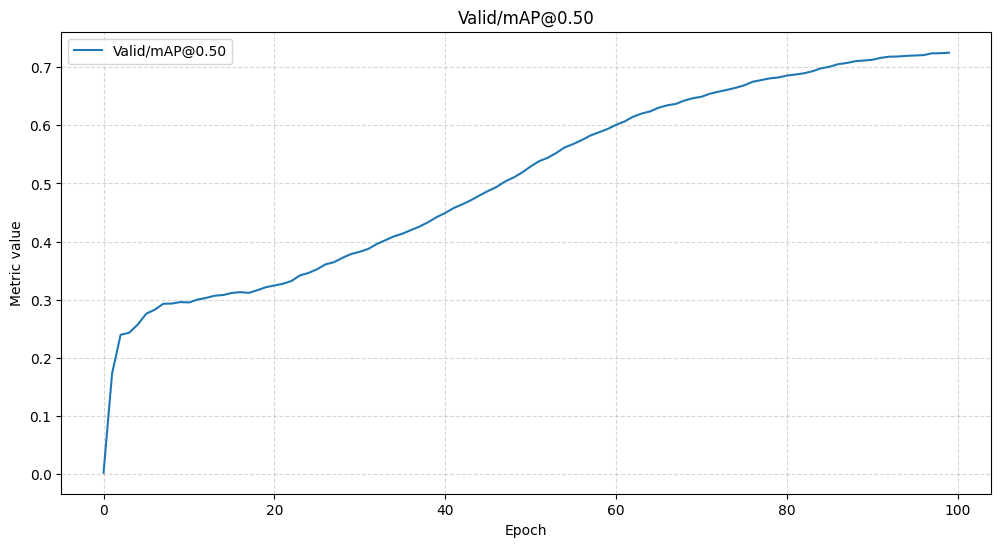

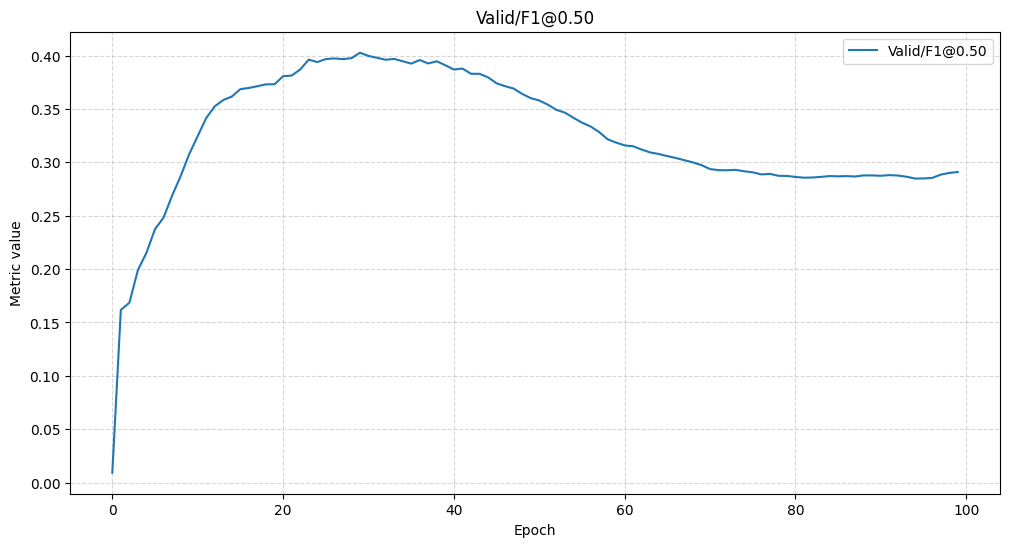

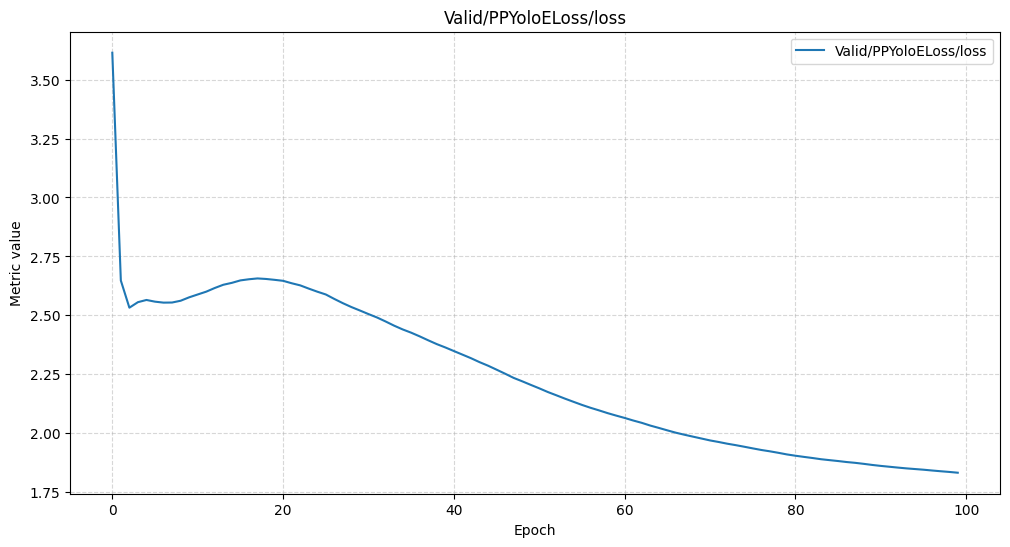

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

if not metrics_recorder.epoch_history:
    raise RuntimeError("Run the training cell first so that metrics_recorder captures epoch metrics.")

metrics_df = pd.DataFrame(metrics_recorder.epoch_history).sort_values("epoch").reset_index(drop=True)

# SuperGradients prefixes validation metrics with "Valid/"
wanted = [
    "Valid/Recall@0.50",
    "Valid/Precision@0.50",
    "Valid/mAP@0.50",
    "Valid/F1@0.50",
    "Valid/PPYoloELoss/loss",
]
value_columns = [c for c in wanted if c in metrics_df.columns]

if not value_columns:
    raise RuntimeError(f"None of the requested metrics were found. Available: {list(metrics_df.columns)}")

metrics_to_plot = metrics_df[["epoch"] + value_columns]
display(metrics_to_plot)

for metric in value_columns:
    ax = metrics_to_plot.set_index("epoch")[[metric]].plot(figsize=(12, 6))
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Metric value")
    ax.set_title(metric)
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.show()


In [12]:
from super_gradients.training import models

from pathlib import Path
run_root = Path(CHECKPOINT_DIR) / "building_defect_yolo_nas_m"
run_ids = sorted([p.name for p in run_root.glob("RUN_*")])
if not run_ids:
    raise FileNotFoundError(f"No RUN_* folders found in {run_root}")
RUN_ID = run_ids[-1]  # latest run
 
best_model = models.get(
    MODEL_ARCH,
    num_classes=len(dataset_params['classes']),
    # checkpoint_path="C:/ml_dl_cv_files/ObjectDetection-Yolo-TF-Models/Custom-YOLONAS-model/checkpoints/yolonas-demo-m-1/RUN_20240927_182458_276109/average_model.pth"
    checkpoint_path=f"{CHECKPOINT_DIR}/building_defect_yolo_nas_m/{RUN_ID}/average_model.pth"
).to(DEVICE)


[2026-05-09 12:25:17] INFO - checkpoint_utils.py - Successfully loaded model weights from /home/uavc/projects/yolonas-training/checkpoints/building_defect_yolo_nas_m/RUN_20260508_180120_151273/average_model.pth checkpoint.


In [ ]:
import cv2
import random
from pathlib import Path
 
# pick a random test image
image_path = str(random.choice(list(Path("training-data/val/images").glob("*.jpg"))))
image = cv2.imread(image_path)
 
# predict
model_result = best_model.predict(image, conf=0.2)
 
print(model_result.prediction)


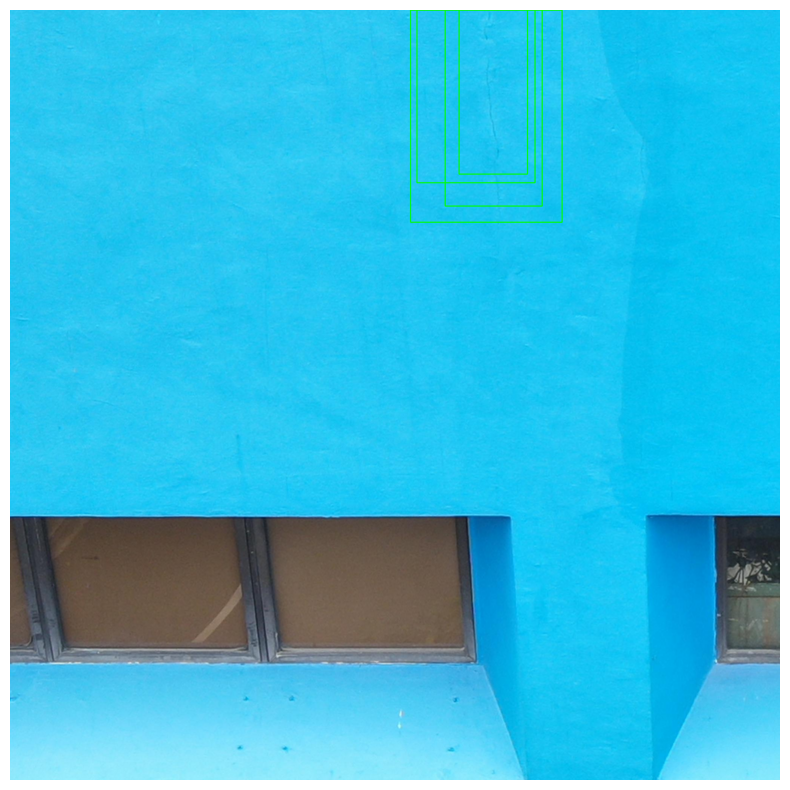

In [14]:
import cv2
import matplotlib.pyplot as plt
 
label_dict = {i: name for i, name in enumerate(dataset_params["classes"])}
 
# Load the image (replace with your image loading method)
image = cv2.imread(image_path)
 
# Bounding boxes, labels, confidence, and label dictionary
bboxes = model_result.prediction.bboxes_xyxy
confidences = model_result.prediction.confidence
labels = model_result.prediction.labels
 
# Draw bounding boxes and labels on the image
for i in range(len(bboxes)):
    bbox = bboxes[i]
    confidence = confidences[i]
    label = labels[i]
     
    # Coordinates of the bounding box
    x1, y1, x2, y2 = [int(coord) for coord in bbox]
 
    # Draw the rectangle
    cv2.rectangle(image, (x1, y1), (x2, y2), color=(0, 255, 0), thickness=2)
 
    # Create label text with confidence
    label_text = f"{label_dict[label]}: {confidence:.2f}"
 
    # Put the label text above the bounding box
    cv2.putText(image, label_text, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 
                fontScale=0.5, color=(255, 255, 255), thickness=1, lineType=cv2.LINE_AA)
 
# Convert BGR to RGB for displaying in matplotlib
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
 
# Display the image using matplotlib
plt.figure(figsize=(10, 10))
plt.imshow(image_rgb)
plt.axis('off')  # Turn off axis
plt.show()
